# Machine Learning e Inteligência de Negócios na Detecção de Fraudes em Cartões de Crédito
### Recorte: o golpe da maquininha

**Projeto Integrador de Ciência dos Dados I – UFMS Digital – 2026/2 – T01**
Autor: Rubens Lima Araújo

Este notebook reúne, em um só lugar, toda a análise de dados do projeto de extensão. Ele
acompanha o Relatório Final (Módulo 3) e pode ser executado do início ao fim para reproduzir
os números e os gráficos do relatório.

| Seção | Etapa do *Design Thinking* | Conteúdo |
|---|---|---|
| 1 | — | Bibliotecas e configuração |
| 2 | Ouvir | O caso real (linha do tempo do golpe) e as reclamações públicas (agregadas) |
| 3 | Criar | Preparação dos dados e qualidade da base do Kaggle |
| 4 | Criar | Análise exploratória, com recorte das compras presenciais |
| 5 | Implementar | Modelos: Regressão Logística, Random Forest e Gradient Boosting |
| 6 | Implementar | Caso real avaliado pelo modelo (sem e com o histórico das recusas) |
| 7 | Implementar | Motor de regras R1–R5 em cenários de golpe e de clientes legítimos |
| 8 | — | Conferência com os números do relatório |
| 9 | — | Conclusões |

**Base de dados:** *Credit Card Fraud Detection 2026* (Kaggle), com 20.000 transações
sintéticas. Os valores estão em dólar, e algumas colunas numéricas vêm como texto no formato
brasileiro (`$1.080,71`).

**Privacidade:** nenhuma instituição é identificada. As reclamações públicas aparecem só
agregadas por tipo de instituição.

## 1. Bibliotecas e configuração

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
# O notebook pode ser aberto da pasta notebook/ ou da raiz do projeto
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
CSV = ROOT / "Base de Dados - Projeto Integrador - credit_card_fraud_2026.csv"

C_LEG, C_FRA, C_NEU = "#2E5E8C", "#D9622B", "#8A8F98"   # azul = legítima, laranja = fraude
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("Pasta do projeto:", ROOT.name)

Pasta do projeto: proj-integrador-1


## 2. Ouvir: o caso real e a voz do público-alvo

### 2.1 O golpe sofrido pelo autor
O cartão era **só de crédito**: a função débito nunca foi contratada. Na porta de casa, durante o
dia, o entregador passou o cartão cinco vezes. As três tentativas no débito foram negadas **só por
regra de sistema** (a função não existia), e não pelo antifraude. Em seguida, duas compras no
crédito foram aprovadas. Os intervalos de cerca de 1 minuto entre as tentativas são uma hipótese
de ilustração.

In [2]:
eventos = pd.DataFrame([
    (1, "Débito", 2000.00, "Negada - função débito inexistente"),
    (2, "Débito", 2000.00, "Negada - função débito inexistente"),
    (3, "Débito", 1000.00, "Negada - função débito inexistente"),
    (4, "Crédito", 1010.00, "Aprovada"),
    (5, "Crédito", 1011.00, "Aprovada"),
], columns=["tentativa", "modalidade", "valor_brl", "resposta_real"])
eventos["minuto"] = eventos["tentativa"] - 1
prejuizo = eventos.loc[eventos.resposta_real == "Aprovada", "valor_brl"].sum()
print(f"Prejuízo: R$ {prejuizo:,.2f} em {len(eventos)} tentativas")
eventos

Prejuízo: R$ 2,021.00 em 5 tentativas


,tentativa,modalidade,valor_brl,resposta_real,minuto
0,1,Débito,"2,000.0000",Negada - função débito inexistente,0
1,2,Débito,"2,000.0000",Negada - função débito inexistente,1
2,3,Débito,"1,000.0000",Negada - função débito inexistente,2
3,4,Crédito,"1,010.0000",Aprovada,3
4,5,Crédito,"1,011.0000",Aprovada,4


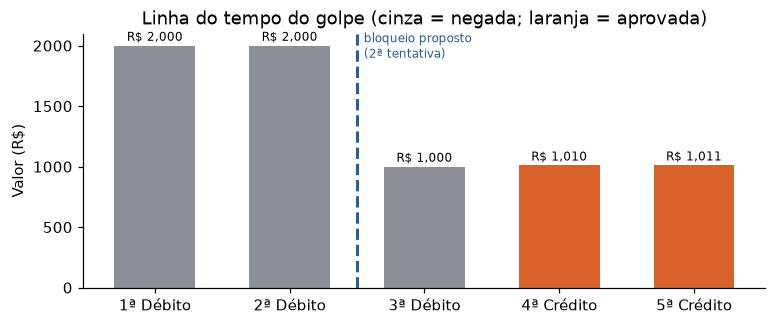

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
cores = [C_FRA if r == "Aprovada" else C_NEU for r in eventos.resposta_real]
ax.bar(eventos.tentativa, eventos.valor_brl, color=cores, width=0.6)
for _, e in eventos.iterrows():
    ax.text(e.tentativa, e.valor_brl + 40, f"R$ {e.valor_brl:,.0f}", ha="center", fontsize=8)
ax.axvline(2.5, color=C_LEG, ls="--", lw=2)
ax.text(2.55, 1900, "bloqueio proposto\n(2ª tentativa)", color=C_LEG, fontsize=8)
ax.set_xticks(eventos.tentativa, [f"{t}ª {m}" for t, m in zip(eventos.tentativa, eventos.modalidade)])
ax.set_ylabel("Valor (R$)"); ax.set_title("Linha do tempo do golpe (cinza = negada; laranja = aprovada)")
plt.show()

### 2.2 Reclamações públicas (pesquisa documental)
A busca por "golpe da maquininha" no Reclame Aqui (08/11/2026) foi feita à mão no navegador, sem
robôs. O script `src/varredura_reclamacoes.py` agrega as 50 empresas mais citadas **por tipo de
instituição**. Aqui é lido só o resultado agregado e anônimo.

In [4]:
V = json.loads((ROOT / "results" / "varredura_reclamacoes.json").read_text(encoding="utf-8"))
ra = V["reclame_aqui"]
print(f"Reclamações na busca: {ra['total_reclamacoes_busca']:,} | 50 empresas mais citadas: "
      f"{ra['reclamacoes_top50']:,} | relatos lidos: {ra['leitura_qualitativa_n']}")
pd.DataFrame(ra["por_tipo"]).T.rename(columns={"pct_top50": "% das 50 empresas"})

Reclamações na busca: 6,550 | 50 empresas mais citadas: 5,371 | relatos lidos: 46


,reclamacoes,empresas,% das 50 empresas
Bancos e emissores de cartão,"1,885.0000",22.0000,35.1000
Maquininhas e instituições de pagamento,"1,870.0000",13.0000,34.8000
"Aplicativos de entrega, serviços e transporte","1,466.0000",8.0000,27.3000
"Outros (varejo, serviços e outros)",150.0000,7.0000,2.8000


In [5]:
bol = V["boletim_consumidor_gov_2025"]
pd.Series({
    "Reclamações finalizadas (Consumidor.gov.br, 2025)": f"{bol['reclamacoes_finalizadas']:,}",
    "% do segmento bancos, financeiras e cartões": f"{bol['pct_segmento_bancos_financeiras_cartao']}%",
    "Assunto 'cartão de crédito, débito e loja'": f"{bol['assunto_cartao_credito_debito_loja']:,} "
                                                  f"({bol['pct_assunto_cartao']}%)",
}, name="Boletim Consumidor.gov.br 2025")

Reclamações finalizadas (Consumidor.gov.br, 2025)          2,328,863
% do segmento bancos, financeiras e cartões                   42.84%
Assunto 'cartão de crédito, débito e loja'           433,240 (18.6%)
Name: Boletim Consumidor.gov.br 2025, dtype: str

## 3. Criar: preparação dos dados
Seis colunas numéricas estão gravadas como texto no formato brasileiro (`$1.080,71`, `13,54`).
Elas são convertidas para número. Em seguida, verificam-se ausentes, duplicados e o
desbalanceamento das classes.

In [6]:
raw = pd.read_csv(CSV)
NUM_TXT = ["amount_usd", "hours_since_last_txn", "distance_from_home_km",
           "account_balance_usd", "velocity_score", "merchant_risk_score"]

def br_to_float(s: pd.Series) -> pd.Series:
    """Converte '$1.080,71' -> 1080.71."""
    return (s.astype(str).str.replace("$", "", regex=False).str.replace(".", "", regex=False)
            .str.replace(",", ".", regex=False).astype(float))

print("Antes:", raw[NUM_TXT].iloc[0].to_dict())
df = raw.copy()
for c in NUM_TXT:
    df[c] = br_to_float(df[c])
print("Depois:", df[NUM_TXT].iloc[0].to_dict())
print(f"\n{df.shape[0]:,} linhas x {df.shape[1]} colunas | ausentes: {df.isna().sum().sum()} | "
      f"duplicadas: {df.drop(columns='transaction_id').duplicated().sum()}")

Antes: {'amount_usd': '$42,86', 'hours_since_last_txn': '13,54', 'distance_from_home_km': '22,35', 'account_balance_usd': '$1.080,71', 'velocity_score': '0,1', 'merchant_risk_score': '42,3'}
Depois: {'amount_usd': 42.86, 'hours_since_last_txn': 13.54, 'distance_from_home_km': 22.35, 'account_balance_usd': 1080.71, 'velocity_score': 0.1, 'merchant_risk_score': 42.3}



20,000 linhas x 26 colunas | ausentes: 0 | duplicadas: 0


In [7]:
classe = df["is_fraud"].value_counts().rename({0: "legítima", 1: "fraude"})
print(classe.to_string())
print(f"Taxa de fraude: {100 * df.is_fraud.mean():.2f}%  ->  classes muito desbalanceadas;"
      " a acurácia engana, por isso usamos recall, precisão e PR-AUC.")

is_fraud
legítima    19661
fraude        339
Taxa de fraude: 1.70%  ->  classes muito desbalanceadas; a acurácia engana, por isso usamos recall, precisão e PR-AUC.


In [8]:
# A base é sintética: há combinações que não existem no mundo real
pd.crosstab(df.device_type, df.channel)

channel,ATM,Contactless,In-App,Online,POS
device_type,,,,,
ATM Machine,79,179,158,337,252
Android Phone,392,934,865,1854,1458
Mac,100,240,209,465,345
POS Terminal,185,536,558,1101,782
Smart Watch,69,172,158,334,275
Tablet,90,189,190,396,296
Windows PC,202,441,423,898,659
iPhone,257,709,664,1425,1124


## 4. Criar: análise exploratória
### 4.1 Canal, autenticação e valor

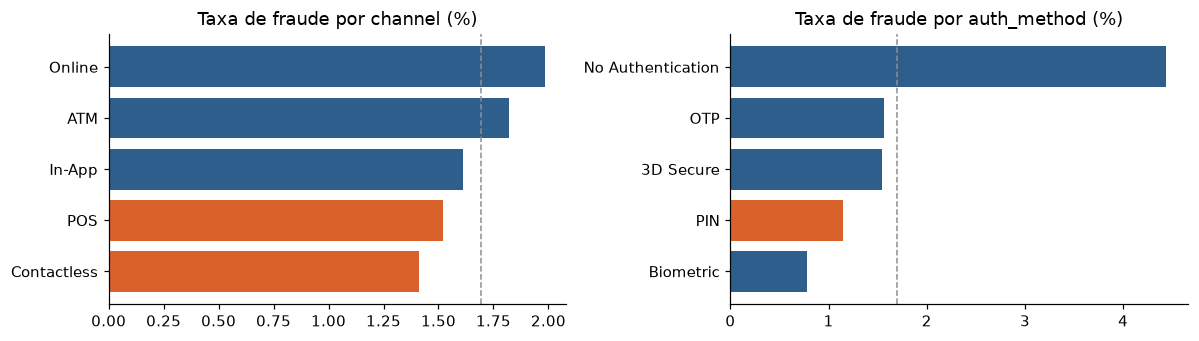

,taxa_pct,fraudes,n
channel,,,
Online,1.9824,135,6810
ATM,1.8195,25,1374
In-App,1.6124,52,3225
POS,1.5219,79,5191
Contactless,1.4118,48,3400


In [9]:
def taxa(col):
    t = df.groupby(col)["is_fraud"].agg(taxa_pct="mean", fraudes="sum", n="count")
    t["taxa_pct"] *= 100
    return t.sort_values("taxa_pct", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, col in zip(axes, ["channel", "auth_method"]):
    t = taxa(col)
    destaque = {"POS", "Contactless", "PIN"}
    ax.barh(t.index[::-1], t.taxa_pct[::-1], color=[C_FRA if i in destaque else C_LEG for i in t.index[::-1]])
    ax.axvline(100 * df.is_fraud.mean(), color=C_NEU, ls="--", lw=1)
    ax.set_title(f"Taxa de fraude por {col} (%)")
plt.tight_layout(); plt.show()
display(taxa("channel"))

Compras **presenciais** (maquininha e aproximação) e com **senha (PIN)** ficam *abaixo* da média.
No agregado, uma compra presencial com senha parece segura, e é essa aparência que o golpe da
maquininha explora.

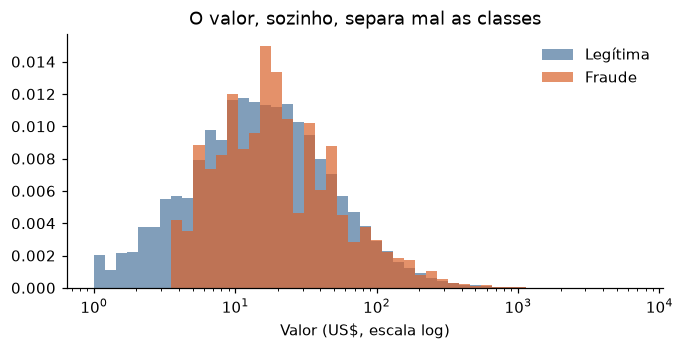

is_fraud
mediana legítima   57.3500
mediana fraude     69.7700
Name: amount_usd, dtype: float64

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.logspace(np.log10(max(df.amount_usd.min(), 0.5)), np.log10(df.amount_usd.max()), 50)
ax.hist(df.loc[df.is_fraud == 0, "amount_usd"], bins=bins, density=True, alpha=0.6, color=C_LEG, label="Legítima")
ax.hist(df.loc[df.is_fraud == 1, "amount_usd"], bins=bins, density=True, alpha=0.7, color=C_FRA, label="Fraude")
ax.set_xscale("log"); ax.set_xlabel("Valor (US$, escala log)"); ax.legend(frameon=False)
ax.set_title("O valor, sozinho, separa mal as classes"); plt.show()
df.groupby("is_fraud")["amount_usd"].median().rename({0: "mediana legítima", 1: "mediana fraude"})

### 4.2 Sinais de tentativas repetidas (os sinais do caso real)

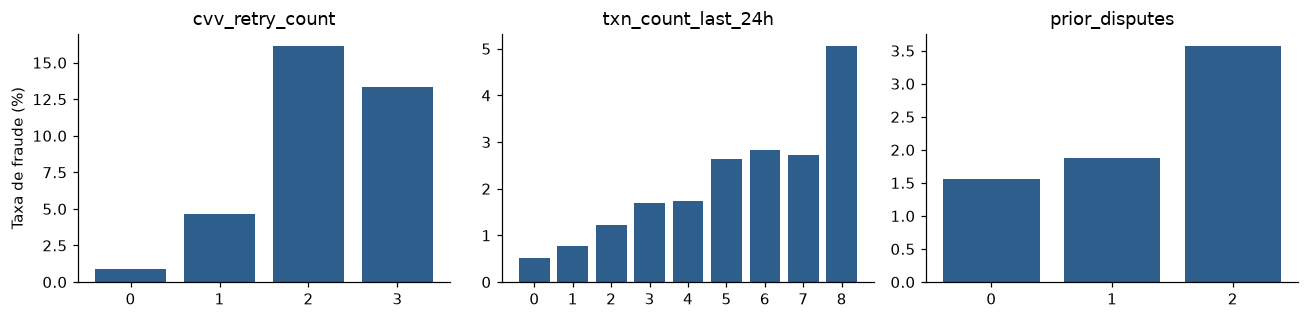

,taxa,n
cvv_retry_count,,
0,0.9185,16658
1,4.6534,3073
2,16.1417,254
3,13.3333,15


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (col, clip) in zip(axes, [("cvv_retry_count", None), ("txn_count_last_24h", 8), ("prior_disputes", 2)]):
    s = df[col].clip(upper=clip) if clip else df[col]
    t = df.groupby(s)["is_fraud"].mean() * 100
    ax.bar(t.index.astype(str), t.values, color=C_LEG); ax.set_title(col)
axes[0].set_ylabel("Taxa de fraude (%)"); plt.tight_layout(); plt.show()
(df.groupby("cvv_retry_count")["is_fraud"].agg(taxa=lambda s: 100 * s.mean(), n="count"))

In [12]:
pres = df[df.channel.isin(["POS", "Contactless"])]
print(f"Recorte presencial: {len(pres):,} transações, taxa {100 * pres.is_fraud.mean():.2f}%")
print(f"  estabelecimento novo:     {100 * pres.loc[pres.is_new_merchant, 'is_fraud'].mean():.2f}%")
print(f"  estabelecimento conhecido: {100 * pres.loc[~pres.is_new_merchant, 'is_fraud'].mean():.2f}%")
r = pres[pres.merchant_category == "Restaurants"]
print(f"  restaurantes presenciais:  {100 * r.is_fraud.mean():.2f}% ({r.is_fraud.sum()} fraudes em {len(r):,})"
      "  <- base sintética, sem categoria de delivery: tratado como limitação")

Recorte presencial: 8,591 transações, taxa 1.48%
  estabelecimento novo:     3.13%
  estabelecimento conhecido: 0.98%
  restaurantes presenciais:  0.64% (7 fraudes em 1,094)  <- base sintética, sem categoria de delivery: tratado como limitação


### 4.3 Horário: presencial × não presencial
Faixas de 4 horas com intervalo de confiança de Wilson (95%) e teste qui-quadrado (noite × dia).

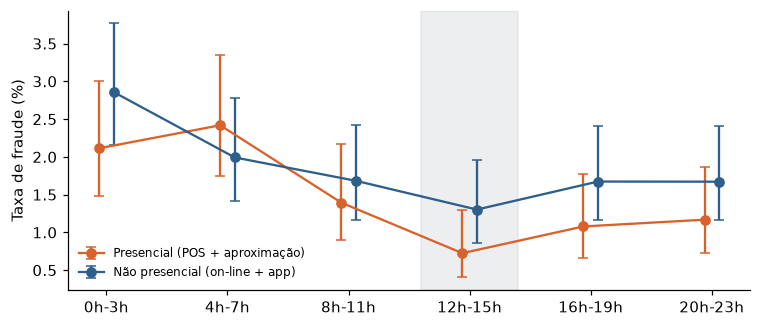

,noite 22h-5h (%),dia 6h-21h (%),p-valor qui²,12h-15h (%)
grupo,,,,
Presencial (POS + aproximação),2.3115,1.0728,0.0000,0.7251
Não presencial (on-line + app),2.4852,1.5477,0.0014,1.3025


In [13]:
def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    m = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (c - m), 100 * (c + m)

GRUPOS = {"Presencial (POS + aproximação)": ["POS", "Contactless"], "Não presencial (on-line + app)": ["Online", "In-App"]}
FAIXAS = [(0, 3), (4, 7), (8, 11), (12, 15), (16, 19), (20, 23)]
NOITE = [22, 23, 0, 1, 2, 3, 4, 5]
fig, ax = plt.subplots(figsize=(8, 3.3)); linhas = []
for (nome, canais), cor, d in zip(GRUPOS.items(), [C_FRA, C_LEG], [-0.06, 0.06]):
    g = df[df.channel.isin(canais)]
    tx, lo, hi = [], [], []
    for a, b in FAIXAS:
        s = g[g.time_of_day_hour.between(a, b)]; k, n = s.is_fraud.sum(), len(s)
        tx.append(100 * k / n); l, h = wilson(k, n); lo.append(l); hi.append(h)
    tx, lo, hi = map(np.array, (tx, lo, hi))
    ax.errorbar(np.arange(6) + d, tx, yerr=[tx - lo, hi - tx], color=cor, marker="o", capsize=3, label=nome)
    gn = g.time_of_day_hour.isin(NOITE)
    p = stats.chi2_contingency(pd.crosstab(gn, g.is_fraud))[1]
    linhas.append({"grupo": nome, "noite 22h-5h (%)": 100 * g.loc[gn, "is_fraud"].mean(),
                   "dia 6h-21h (%)": 100 * g.loc[~gn, "is_fraud"].mean(), "p-valor qui²": p,
                   "12h-15h (%)": tx[3]})
ax.set_xticks(range(6), [f"{a}h-{b}h" for a, b in FAIXAS]); ax.axvspan(2.6, 3.4, color=C_NEU, alpha=0.15)
ax.set_ylabel("Taxa de fraude (%)"); ax.legend(frameon=False, fontsize=8); plt.show()
pd.DataFrame(linhas).set_index("grupo")

O efeito da noite também aparece nas compras presenciais, então ele **não** se explica pelo canal
on-line. A faixa do caso (12h–15h, presencial, faixa cinza) é a de **menor** taxa. O modelo
tende a aprovar uma compra assim, e o alerta só poderia vir da sequência de recusas.

## 5. Implementar: modelos
Divisão estratificada 75% / 25% (semente 42). As variáveis categóricas recebem codificação
*one-hot*, as numéricas são padronizadas e os modelos usam pesos por classe. Há três modelos:

* **Regressão Logística**: linear e interpretável (melhor modelo do relatório parcial);
* **Random Forest**: no relatório parcial, quase não alertava no limiar 0,5 (melhoria: ajustar o limiar);
* **Gradient Boosting** (`HistGradientBoostingClassifier`): melhoria prometida no parcial, com uma pequena grade de hiperparâmetros.

O **limiar de decisão** é escolhido só no treino, com probabilidades fora da dobra da validação
cruzada. O teste é usado só para medir.

In [14]:
CAT = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
BOOL = ["is_foreign_transaction", "is_new_merchant", "used_vpn", "ip_country_mismatch",
        "billing_shipping_mismatch", "is_ai_generated_scam_attempt"]
NUM = ["amount_usd", "hours_since_last_txn", "txn_count_last_24h", "distance_from_home_km",
       "card_age_months", "customer_age", "account_balance_usd", "cvv_retry_count",
       "velocity_score", "time_of_day_hour", "day_of_week", "merchant_risk_score", "prior_disputes"]
X = df[CAT + BOOL + NUM].copy(); X[BOOL] = X[BOOL].astype(int); y = df["is_fraud"].values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
pre = lambda: ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
                                 ("num", StandardScaler(), NUM + BOOL)])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"treino {len(X_tr):,} ({y_tr.sum()} fraudes) | teste {len(X_te):,} ({y_te.sum()} fraudes)")

treino 15,000 (254 fraudes) | teste 5,000 (85 fraudes)


In [15]:
def gb(lr, folhas, msl):
    return Pipeline([("pre", pre()), ("clf", HistGradientBoostingClassifier(
        learning_rate=lr, max_iter=300 if lr < 0.1 else 120, max_leaf_nodes=folhas, min_samples_leaf=msl,
        l2_regularization=1.0, class_weight="balanced", random_state=SEED))])

grade = []
for lr in (0.03, 0.1):
    for folhas in (4, 15):
        for msl in (20, 100):
            s = cross_val_score(gb(lr, folhas, msl), X_tr, y_tr, cv=cv, scoring="average_precision", n_jobs=-1)
            grade.append({"learning_rate": lr, "max_leaf_nodes": folhas, "min_samples_leaf": msl, "cv5_pr_auc": s.mean()})
grade = pd.DataFrame(grade).sort_values("cv5_pr_auc", ascending=False)
melhor_gb = grade.iloc[0]
grade

,learning_rate,max_leaf_nodes,min_samples_leaf,cv5_pr_auc
1,0.0300,4,100,0.3407
5,0.1000,4,100,0.3404
4,0.1000,4,20,0.3391
0,0.0300,4,20,0.3368
2,0.0300,15,20,0.2748
3,0.0300,15,100,0.2678
7,0.1000,15,100,0.2663
6,0.1000,15,20,0.2581


In [16]:
modelos = {
    "Regressão Logística": Pipeline([("pre", pre()), ("clf", LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=SEED))]),
    "Random Forest": Pipeline([("pre", pre()), ("clf", RandomForestClassifier(
        n_estimators=400, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting": gb(melhor_gb.learning_rate, int(melhor_gb.max_leaf_nodes), int(melhor_gb.min_samples_leaf)),
}

def metr(yt, p, t):
    yh = (p >= t).astype(int); tn, fp, fn, tp = confusion_matrix(yt, yh).ravel()
    return {"limiar": t, "recall": recall_score(yt, yh), "precisão": precision_score(yt, yh, zero_division=0),
            "F1": f1_score(yt, yh, zero_division=0), "fraudes barradas": tp, "falsos positivos": fp,
            "% alertadas": 100 * yh.mean()}

def limiar_recall(yt, p, alvo=0.80):
    pr, rc, th = precision_recall_curve(yt, p)
    return float(th[np.where(rc[:-1] >= alvo)[0].max()])

res, probas = {}, {}
for nome, m in modelos.items():
    oof = cross_val_predict(m, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    cv_pr = np.mean([average_precision_score(y_tr[te], oof[te]) for _, te in cv.split(X_tr, y_tr)])
    t80 = limiar_recall(y_tr, oof)
    m.fit(X_tr, y_tr); p = m.predict_proba(X_te)[:, 1]; probas[nome] = p
    res[nome] = {"PR-AUC (CV treino)": cv_pr, "PR-AUC (teste)": average_precision_score(y_te, p),
                 "ROC-AUC (teste)": roc_auc_score(y_te, p),
                 **{f"{k} @0,5": v for k, v in metr(y_te, p, 0.5).items() if k in ("recall", "fraudes barradas")},
                 **{f"{k} @limiar ajustado": v for k, v in metr(y_te, p, t80).items()}}
tab_modelos = pd.DataFrame(res).T
final = tab_modelos["PR-AUC (CV treino)"].idxmax()
print("Modelo final (escolhido pela validação cruzada):", final)
tab_modelos

Modelo final (escolhido pela validação cruzada): Regressão Logística


,PR-AUC (CV treino),PR-AUC (teste),ROC-AUC (teste),"recall @0,5","fraudes barradas @0,5",limiar @limiar ajustado,recall @limiar ajustado,precisão @limiar ajustado,F1 @limiar ajustado,fraudes barradas @limiar ajustado,falsos positivos @limiar ajustado,% alertadas @limiar ajustado
Regressão Logística,0.3891,0.4358,0.9413,0.8353,71.0000,0.6065,0.7765,0.1387,0.2353,66.0000,410.0000,9.5200
Random Forest,0.2368,0.2279,0.9281,0.0118,1.0000,0.0726,0.8235,0.1057,0.1874,70.0000,592.0000,13.2400
Gradient Boosting,0.3407,0.3383,0.9348,0.8353,71.0000,0.5220,0.8118,0.1104,0.1944,69.0000,556.0000,12.5000


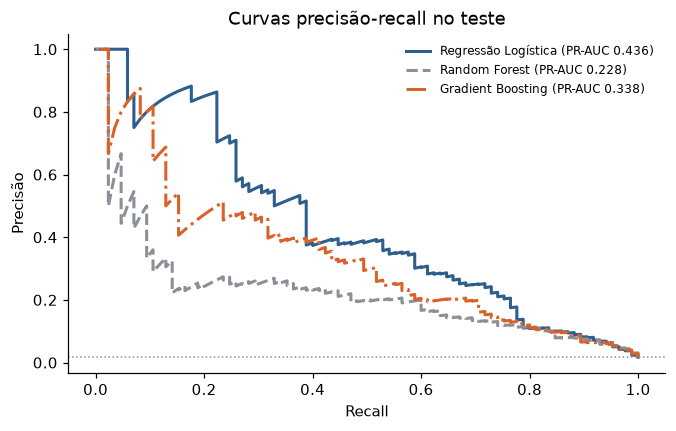

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
for (nome, p), cor, ls in zip(probas.items(), [C_LEG, C_NEU, C_FRA], ["-", "--", "-."]):
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax.plot(rc, pr, color=cor, ls=ls, lw=2, label=f"{nome} (PR-AUC {average_precision_score(y_te, p):.3f})")
ax.axhline(y_te.mean(), color=C_NEU, ls=":", lw=1)
ax.set_xlabel("Recall"); ax.set_ylabel("Precisão"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Curvas precisão-recall no teste"); plt.show()

,recall,precisão,F1,fraudes barradas,falsos positivos,% alertadas
limiar,,,,,,
0.1000,0.9765,0.0420,0.0805,83,1894,39.5400
0.2000,0.9529,0.0586,0.1104,81,1302,27.6600
0.3000,0.9176,0.0741,0.1372,78,974,21.0400
0.5000,0.8353,0.1102,0.1948,71,573,12.8800
0.7000,0.7647,0.1801,0.2915,65,296,7.2200


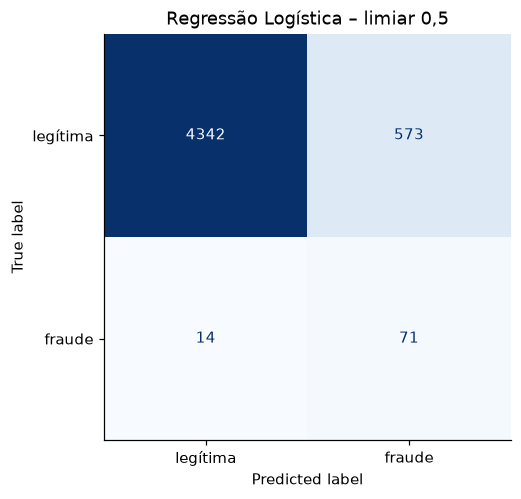

In [18]:
pm = probas[final]
tab_lim = pd.DataFrame([metr(y_te, pm, t) for t in [0.1, 0.2, 0.3, 0.5, 0.7]]).set_index("limiar")
display(tab_lim)
ConfusionMatrixDisplay(confusion_matrix(y_te, (pm >= 0.5).astype(int)),
                       display_labels=["legítima", "fraude"]).plot(cmap="Blues", colorbar=False)
plt.title(f"{final} – limiar 0,5"); plt.show()

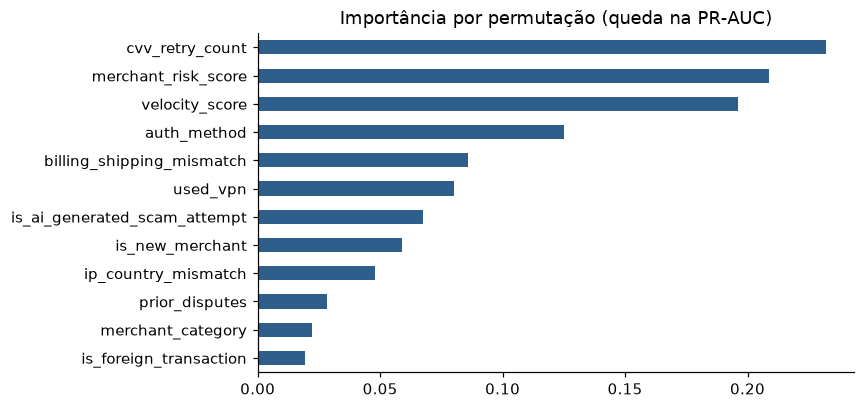

cvv_retry_count       0.2321
merchant_risk_score   0.2087
velocity_score        0.1962
dtype: float64

In [19]:
imp = permutation_importance(modelos[final], X_te, y_te, scoring="average_precision",
                             n_repeats=10, random_state=SEED, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=X_te.columns).sort_values(ascending=False).head(12)
imp_s[::-1].plot.barh(color=C_LEG, figsize=(7, 4), title="Importância por permutação (queda na PR-AUC)")
plt.show()
imp_s.head(3)

**Leitura:** `cvv_retry_count` (novas tentativas) é a variável mais importante. Os dados confirmam
a tese do relato: **tentativas repetidas são o sinal mais forte de fraude**. O *Gradient Boosting*
ajustado superou o Random Forest, mas não a Regressão Logística. Na base sintética, a relação entre
as variáveis e a fraude parece ser quase linear.

## 6. Implementar: o caso real no modelo
A compra aprovada de R$ 1.010 é montada no formato da base (câmbio hipotético de R$ 5,00/US$,
14h, maquininha, senha, estabelecimento novo, demais variáveis na mediana) e avaliada em duas visões:

* **sem contexto**: o que o sistema "vê" quando a recusa técnica não vira dado;
* **com contexto**: as 3 recusas aproximadas por `cvv_retry_count`, `txn_count_last_24h`,
  `hours_since_last_txn` e `velocity_score`.

In [20]:
CAMBIO, HORA_CASO = 5.0, 14
mediana = df[NUM].median()
linha = {"merchant_category": "Restaurants", "card_type": "Mastercard", "auth_method": "PIN",
         "channel": "POS", "device_type": "POS Terminal", "is_foreign_transaction": 0, "is_new_merchant": 1,
         "used_vpn": 0, "ip_country_mismatch": 0, "billing_shipping_mismatch": 0,
         "is_ai_generated_scam_attempt": 0, **{c: mediana[c] for c in NUM}}
linha.update({"amount_usd": 1010 / CAMBIO, "distance_from_home_km": 0.1, "time_of_day_hour": HORA_CASO,
              "prior_disputes": 0})
com = dict(linha, cvv_retry_count=3, txn_count_last_24h=float(mediana["txn_count_last_24h"] + 3),
           hours_since_last_txn=1 / 60, velocity_score=float(df["velocity_score"].quantile(0.99)))
cen = pd.DataFrame([linha, com])[CAT + BOOL + NUM]
caso_modelos = pd.DataFrame({nome: m.predict_proba(cen)[:, 1] for nome, m in modelos.items()},
                            index=["sem contexto das recusas", "com contexto das recusas"]).T
caso_modelos["percentil (sem)"] = [100 * (probas[n] < caso_modelos.loc[n].iloc[0]).mean() for n in caso_modelos.index]
caso_modelos["percentil (com)"] = [100 * (probas[n] < caso_modelos.loc[n].iloc[1]).mean() for n in caso_modelos.index]
caso_modelos

,sem contexto das recusas,com contexto das recusas,percentil (sem),percentil (com)
Regressão Logística,0.0161,0.9904,30.4200,99.5600
Random Forest,0.0049,0.1849,25.5400,98.1400
Gradient Boosting,0.0645,0.8510,33.7800,99.0400


Sem o histórico das recusas, a compra parece comum para os três modelos. Com ele, a
probabilidade dispara. **O problema não é a falta de modelo, e sim a falta de dado.**

## 7. Implementar: motor de regras R1–R5
A base do Kaggle não tem sequência de eventos por cliente nem a modalidade débito/crédito. Por
isso, as regras são testadas em **cenários**: o caso real e quatro golpes inspirados nos padrões
das reclamações públicas, além de quatro situações de clientes legítimos, que servem para medir
os alarmes falsos. Os valores dos cenários são hipotéticos, exceto no caso real.

| Regra | Descrição | Ação |
|---|---|---|
| R1 | Tentativa em modalidade não contratada | alerta |
| R2 | 2 ou mais falhas em 10 min (recusas anteriores + tentativa atual em modalidade inexistente) | **bloqueio** |
| R3 | Valor menor que o de uma tentativa recusada antes (sondagem) | alerta |
| R4 | Valor quase igual (< 2%) a uma tentativa anterior | alerta |
| R5 | Valor acima de 5× o ticket médio do cliente | alerta |

Duas ou mais regras entre R3, R4 e R5 na mesma tentativa também levam ao **bloqueio**.

In [21]:
NEG_MOD, NEG_SALDO, NEG_SENHA, APROV = ("negada: modalidade inexistente", "negada: saldo/limite",
                                       "negada: senha incorreta", "aprovada")
FATOR_TICKET = 5

def motor_regras(contratadas, ticket, eventos, janela=10):
    hist, out, bloqueado = [], [], False
    for (minuto, mod, valor, resp) in eventos:
        jan = [h for h in hist if minuto - h[0] <= janela]
        recusas = [h for h in jan if h[3] != APROV]
        r1 = mod not in contratadas
        r2 = len(recusas) + int(r1) >= 2
        r3 = bool(recusas) and len(jan) >= 2 and valor < max(h[2] for h in jan)
        r4 = any(abs(valor - h[2]) / h[2] < 0.02 for h in jan)
        r5 = valor > FATOR_TICKET * ticket
        bloqueado = bloqueado or r2 or (r3 + r4 + r5) >= 2
        dec = "Bloquear cartão" if bloqueado else ("Alerta: confirmar no app" if (r1 or r3 or r4 or r5) else "Seguir")
        out.append({"minuto": minuto, "modalidade": mod, "valor_brl": valor, "resposta_real": resp,
                    "R1": r1, "R2": r2, "R3": r3, "R4": r4, "R5": r5, "decisao": dec})
        hist.append((minuto, mod, valor, resp))
    return pd.DataFrame(out)

CENARIOS = [
    ("G1 Caso real do autor", "golpe", {"Crédito"}, 60,
     [(0, "Débito", 2000, NEG_MOD), (1, "Débito", 2000, NEG_MOD), (2, "Débito", 1000, NEG_MOD),
      (3, "Crédito", 1010, APROV), (4, "Crédito", 1011, APROV)]),
    ("G2 Sondagem de saldo no débito", "golpe", {"Débito", "Crédito"}, 60,
     [(0, "Débito", 3000, NEG_SALDO), (1, "Débito", 2000, NEG_SALDO), (2, "Débito", 950, APROV)]),
    ("G3 Troca de modalidade após recusa", "golpe", {"Crédito"}, 60,
     [(0, "Débito", 1500, NEG_MOD), (1, "Crédito", 1490, APROV)]),
    ('G4 "Não passou, passa de novo"', "golpe", {"Débito", "Crédito"}, 60,
     [(0, "Crédito", 480, APROV), (1, "Crédito", 485, APROV)]),
    ("G5 Cobrança única alta", "golpe", {"Débito", "Crédito"}, 60, [(0, "Crédito", 1500, APROV)]),
    ("L1 Pedido comum", "legítimo", {"Débito", "Crédito"}, 60, [(0, "Crédito", 62, APROV)]),
    ("L2 Erra a senha uma vez", "legítimo", {"Débito", "Crédito"}, 60,
     [(0, "Débito", 62, NEG_SENHA), (1, "Débito", 62, APROV)]),
    ("L3 Duas compras no mesmo local", "legítimo", {"Débito", "Crédito"}, 60,
     [(0, "Crédito", 62, APROV), (5, "Crédito", 25, APROV)]),
    ("L4 Compra alta planejada", "legítimo", {"Débito", "Crédito"}, 60, [(0, "Crédito", 900, APROV)]),
]
motor_regras(*CENARIOS[0][2:])

,minuto,modalidade,valor_brl,resposta_real,R1,R2,R3,R4,R5,decisao
0,0,Débito,2000,negada: modalidade inexistente,True,False,False,False,True,Alerta: confirmar no app
1,1,Débito,2000,negada: modalidade inexistente,True,True,False,True,True,Bloquear cartão
2,2,Débito,1000,negada: modalidade inexistente,True,True,True,False,True,Bloquear cartão
3,3,Crédito,1010,aprovada,False,True,True,True,True,Bloquear cartão
4,4,Crédito,1011,aprovada,False,True,True,True,True,Bloquear cartão


In [22]:
resumo = []
for nome, tipo, contr, ticket, ev in CENARIOS:
    r = motor_regras(contr, ticket, ev)
    aprov = r.resposta_real == APROV
    primeiro = lambda pref: next((i + 1 for i, d in enumerate(r.decisao) if d.startswith(pref)), None)
    resumo.append({"cenário": nome, "tipo": tipo, "tentativas": len(r),
                   "1º alerta": primeiro("Alerta") or primeiro("Bloquear"), "bloqueio na": primeiro("Bloquear"),
                   "perda real (R$)": r.loc[aprov, "valor_brl"].sum() if tipo == "golpe" else 0,
                   "perda com bloqueio (R$)": r.loc[aprov & (r.decisao != "Bloquear cartão"), "valor_brl"].sum() if tipo == "golpe" else 0,
                   "perda com bloqueio + alerta (R$)": r.loc[aprov & (r.decisao == "Seguir"), "valor_brl"].sum() if tipo == "golpe" else 0,
                   "alarmes falsos": (r.decisao != "Seguir").sum() if tipo == "legítimo" else 0})
resumo = pd.DataFrame(resumo).set_index("cenário")
resumo

,tipo,tentativas,1º alerta,bloqueio na,perda real (R$),perda com bloqueio (R$),perda com bloqueio + alerta (R$),alarmes falsos
cenário,,,,,,,,
G1 Caso real do autor,golpe,5,1.0000,2.0000,2021,0,0,0
G2 Sondagem de saldo no débito,golpe,3,1.0000,3.0000,950,0,0,0
G3 Troca de modalidade após recusa,golpe,2,1.0000,2.0000,1490,0,0,0
"G4 ""Não passou, passa de novo""",golpe,2,1.0000,2.0000,965,480,0,0
G5 Cobrança única alta,golpe,1,1.0000,NaN,1500,1500,0,0
L1 Pedido comum,legítimo,1,NaN,NaN,0,0,0,0
L2 Erra a senha uma vez,legítimo,2,2.0000,NaN,0,0,0,1
L3 Duas compras no mesmo local,legítimo,2,NaN,NaN,0,0,0,0
L4 Compra alta planejada,legítimo,1,1.0000,NaN,0,0,0,1


In [23]:
g = resumo[resumo.tipo == "golpe"]; l = resumo[resumo.tipo == "legítimo"]
print(f"Golpes bloqueados: {g['bloqueio na'].notna().sum()} de {len(g)}")
print(f"Perda total: real R$ {g['perda real (R$)'].sum():,.0f} | só com bloqueio R$ {g['perda com bloqueio (R$)'].sum():,.0f}"
      f" | com bloqueio + alerta no app R$ {g['perda com bloqueio + alerta (R$)'].sum():,.0f}")
print(f"Clientes legítimos com alerta: {(l['alarmes falsos'] > 0).sum()} de {len(l)} | bloqueados: 0")

Golpes bloqueados: 4 de 5
Perda total: real R$ 6,926 | só com bloqueio R$ 1,980 | com bloqueio + alerta no app R$ 0
Clientes legítimos com alerta: 2 de 4 | bloqueados: 0


## 8. Conferência com os números do relatório
Os números do relatório saem de `results/metricas.json` (gerado por `src/analise_preliminar.py`) e
de `results/metricas_final.json` (gerado por `src/solucao_final.py`). Esta célula confere se o
notebook chega aos mesmos valores.

In [24]:
M = json.loads((ROOT / "results" / "metricas.json").read_text(encoding="utf-8"))
MF = json.loads((ROOT / "results" / "metricas_final.json").read_text(encoding="utf-8"))
checagens = {
    "taxa de fraude (%)": (100 * df.is_fraud.mean(), M["classe"]["taxa_fraude_pct"]),
    "RL PR-AUC CV": (tab_modelos.loc["Regressão Logística", "PR-AUC (CV treino)"], MF["modelos"]["Regressão Logística"]["cv5_pr_auc_media"]),
    "RL PR-AUC teste": (tab_modelos.loc["Regressão Logística", "PR-AUC (teste)"], M["modelos"]["Regressão Logística"]["teste_pr_auc"]),
    "RF PR-AUC teste": (tab_modelos.loc["Random Forest", "PR-AUC (teste)"], MF["modelos"]["Random Forest"]["teste_pr_auc"]),
    "GB PR-AUC teste": (tab_modelos.loc["Gradient Boosting", "PR-AUC (teste)"], MF["modelos"]["Gradient Boosting"]["teste_pr_auc"]),
    "caso: prob. sem contexto": (caso_modelos.loc["Regressão Logística"].iloc[0], M["caso_real_no_modelo"]["prob_sem_contexto_das_recusas"]),
    "caso: prob. com contexto": (caso_modelos.loc["Regressão Logística"].iloc[1], M["caso_real_no_modelo"]["prob_com_contexto_das_recusas"]),
    "regras: perda real total": (g["perda real (R$)"].sum(), MF["resumo_regras"]["perda_real_total_brl"]),
    "regras: perda só bloqueio": (g["perda com bloqueio (R$)"].sum(), MF["resumo_regras"]["perda_so_bloqueio_total_brl"]),
}
conf = pd.DataFrame(checagens, index=["notebook", "relatório"]).T
conf["confere"] = np.isclose(conf.notebook, conf["relatório"], atol=6e-3)
assert conf.confere.all(), conf[~conf.confere]
conf

,notebook,relatório,confere
taxa de fraude (%),1.6950,1.7000,True
RL PR-AUC CV,0.3891,0.3891,True
RL PR-AUC teste,0.4358,0.4358,True
RF PR-AUC teste,0.2279,0.2279,True
GB PR-AUC teste,0.3383,0.3383,True
caso: prob. sem contexto,0.0161,0.0161,True
caso: prob. com contexto,0.9904,0.9904,True
regras: perda real total,"6,926.0000","6,926.0000",True
regras: perda só bloqueio,"1,980.0000","1,980.0000",True


## 9. Conclusões

1. **A base confirma o sinal do caso real:** tentativas repetidas (`cvv_retry_count`) são a variável
   mais importante, e a taxa de fraude cresce com o número de transações recentes.
2. **O perfil do golpe parece seguro para o modelo:** compra presencial, com senha, de dia, perto de casa.
   Sem o histórico das recusas, a compra do caso real fica entre as de menor risco.
3. **A Regressão Logística segue como modelo final.** O Random Forest com limiar ajustado passou a
   alertar, e o Gradient Boosting ajustado superou o RF, mas nenhum dos dois superou o modelo linear.
4. **As regras completam o modelo:** transformar a recusa técnica em dado e aplicar R1–R5 barra a maioria
   dos golpes simulados já na 2ª ou 3ª tentativa, sem bloquear nenhum cliente legítimo dos cenários.
   O caso de cobrança única alta (G5) mostra o limite das regras. Nele, a defesa é o consumidor conferir
   o valor no visor, como orienta a cartilha.

**Limitações:** a base é sintética e não tem modalidade débito/crédito, histórico por cliente nem
categoria de delivery. Os cenários do motor de regras são hipotéticos, e o câmbio e a hora do caso
são hipóteses declaradas.